# PnP-Flow raw SEM square-mask inpainting

This notebook loads a raw NFFA-SEM image, applies either an external missing-pixel mask or a large synthetic square mask, runs tiled multi-GPU PnP-Flow inpainting over the entire mask, and compares the reconstruction with the original image.

In [1]:
from pathlib import Path
import os

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

repo_root = Path.cwd().resolve()
if not (repo_root / 'pnpflow').is_dir():
    repo_root = repo_root.parent
if not (repo_root / 'pnpflow').is_dir():
    raise RuntimeError('Open this notebook from the PnP-Flow repository or its notebooks/ directory.')
os.chdir(repo_root)

from pnpflow.degradations import FixedMaskInpainting
from pnpflow.utils import define_model

DATASET_NAME = 'sem_nffa_all10'
model_root = repo_root / 'model' / DATASET_NAME / 'ot'
RUN_NAME = '20260713_112747_sem_nffa_all10_ot'
run_dir = model_root / RUN_NAME
assert run_dir.is_dir(), f'SEM run not found: {run_dir}'
checkpoint_path = run_dir / 'model_final.pt'


# DATASET_NAME = 'sem_nffa'
# RUN_NAME = '20260712_150348_sem_nffa_ot'
# CHECKPOINT_NAME = 'model_final.pt'
# checkpoint_path = repo_root / 'model' / DATASET_NAME / 'ot' / RUN_NAME / CHECKPOINT_NAME
assert checkpoint_path.is_file(), f'Checkpoint not found: {checkpoint_path}'

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(0)
print(f'Repository: {repo_root}')
print(f'Checkpoint: {checkpoint_path}')
print(f'Device: {device}')


/data2/marci/bselvaku/conda/envs/torchlearn/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Repository: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow
Checkpoint: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/model/sem_nffa_all10/ot/20260713_112747_sem_nffa_all10_ot/model_final.pt
Device: cuda:0


In [2]:
class ModelArgs:
    model = 'ot'
    num_channels = 1
    dim_image = 128

model, _ = define_model(ModelArgs())
state_dict = torch.load(checkpoint_path, map_location=device, weights_only=True)
model.load_state_dict(state_dict)
model.to(device).eval()

# Optional: split every tile batch over all selected visible GPUs.
USE_MULTI_GPU = True
GPU_IDS = list(range(torch.cuda.device_count()))
if USE_MULTI_GPU and device.type == 'cuda' and len(GPU_IDS) > 1:
    model = torch.nn.DataParallel(model, device_ids=GPU_IDS, output_device=GPU_IDS[0])
    print(f'Multi-GPU inference enabled on {len(GPU_IDS)} GPUs: {GPU_IDS}')
else:
    print(f'Single-device inference on {device}')


Multi-GPU inference enabled on 4 GPUs: [0, 1, 2, 3]


In [13]:
# This 3072 x 2304 Particles image can contain the same 928 x 928 synthetic
# missing square used in the HAADF experiment. Set RAW_SEM_IMAGE to another
# JPEG under RAW_SEM_ROOT if desired.
RAW_SEM_ROOT = Path('/data2/marci/bselvaku/nffa_sem/raw_images')
RAW_SEM_IMAGE = RAW_SEM_ROOT / 'Particles/L2_17ceaf7ddba729f13ec26d4825f8cdf9.jpg'

# Preferred for real damage: a same-sized .npy boolean or 0/1 mask.
# True/nonzero means missing and must be reconstructed.
MISSING_MASK_PATH = None  # Example: RAW_SEM_IMAGE.with_name(f'{RAW_SEM_IMAGE.stem}_missing.npy')

# The PnP-Flow checkpoint was trained on 128 x 128 grayscale patches.
TILE_SIZE = 128
TILE_STRIDE = 64
INFERENCE_BATCH_SIZE = 1024
SQUARE_SIZE = 100
NOISE_STD = 0.01
STEPS_PNP = 50
NUM_SAMPLES = 5
LR_PNP = 1.0
ALPHA = 1.0

with Image.open(RAW_SEM_IMAGE) as image:
    raw_sem = np.asarray(image.convert('L'), dtype=np.float32)
if raw_sem.ndim != 2 or not np.isfinite(raw_sem).all():
    raise ValueError(f'Expected a finite 2D grayscale image: {RAW_SEM_IMAGE}')

height, width = raw_sem.shape
if MISSING_MASK_PATH is not None:
    missing = np.load(MISSING_MASK_PATH).astype(bool)
    if missing.shape != raw_sem.shape:
        raise ValueError(f'Mask shape {missing.shape} does not match image shape {raw_sem.shape}')
else:
    if SQUARE_SIZE > min(height, width):
        raise ValueError(f'SQUARE_SIZE={SQUARE_SIZE} is larger than image shape {raw_sem.shape}')
    square_top = (height - SQUARE_SIZE) // 2
    square_left = (width - SQUARE_SIZE) // 2
    missing = np.zeros(raw_sem.shape, dtype=bool)
    missing[square_top:square_top + SQUARE_SIZE, square_left:square_left + SQUARE_SIZE] = True

if not missing.any():
    raise ValueError('The missing-pixel mask is empty.')
missing_rows, missing_cols = np.where(missing)
mask_top, mask_bottom = int(missing_rows.min()), int(missing_rows.max() + 1)
mask_left, mask_right = int(missing_cols.min()), int(missing_cols.max() + 1)

# Match SEM patch preparation: grayscale, 1st/99th-percentile clipping, then [-1, 1].
low, high = np.percentile(raw_sem[~missing], (1, 99))
if not high > low:
    raise ValueError('Image has no usable intensity range for percentile normalization.')
raw_sem_norm = 2 * np.clip((raw_sem - low) / (high - low), 0, 1) - 1
observed_raw = raw_sem.copy()
observed_raw[missing] = 0

print(f'Raw image: {RAW_SEM_IMAGE}')
print(f'X size (width): {width} pixels; Y size (height): {height} pixels')
print(f'Missing-mask bounds: x={mask_left}:{mask_right}, y={mask_top}:{mask_bottom}')
print(f'Missing fraction: {missing.mean():.2%} ({missing.sum():,} pixels)')
print(f'Normalization range: [{low:.5g}, {high:.5g}]')


Raw image: /data2/marci/bselvaku/nffa_sem/raw_images/Particles/L2_17ceaf7ddba729f13ec26d4825f8cdf9.jpg
X size (width): 3072 pixels; Y size (height): 2304 pixels
Missing-mask bounds: x=1486:1586, y=1102:1202
Missing fraction: 0.14% (10,000 pixels)
Normalization range: [0, 255]


In [14]:
@torch.inference_mode()
def pnp_flow_inpaint(observed, known_mask):
    """Run PnP-Flow on a batch of 128 x 128 tiles."""
    degradation = FixedMaskInpainting(known_mask)
    x = degradation.H_adj(observed).clone()
    known = degradation.H_adj(torch.ones_like(observed))
    lr = NOISE_STD ** 2 * LR_PNP

    for iteration in range(STEPS_PNP):
        t = torch.full((len(x),), iteration / STEPS_PNP, device=x.device)
        lr_t = lr * (1 - t).pow(ALPHA).view(-1, 1, 1, 1)
        z = x - lr_t * degradation.H_adj(degradation.H(x) - observed) / (NOISE_STD ** 2)

        x_new = torch.zeros_like(x)
        for _ in range(NUM_SAMPLES):
            t_view = t.view(-1, 1, 1, 1)
            z_tilde = t_view * z + (1 - t_view) * torch.randn_like(z)
            x_new += z_tilde + (1 - t_view) * model(z_tilde, t)
        x = known * observed + (1 - known) * (x_new / NUM_SAMPLES)

    return x.clamp(-1, 1)

def tile_starts(length):
    if length <= TILE_SIZE:
        return [0]
    starts = list(range(0, length - TILE_SIZE + 1, TILE_STRIDE))
    if starts[-1] != length - TILE_SIZE:
        starts.append(length - TILE_SIZE)
    return starts

def inpaint_masked_image(image_norm, missing_mask):
    """Fill every True mask pixel using overlapping 128 x 128 model tiles."""
    image_height, image_width = image_norm.shape
    padded_height, padded_width = max(image_height, TILE_SIZE), max(image_width, TILE_SIZE)
    pad = ((0, padded_height - image_height), (0, padded_width - image_width))
    image_pad = np.pad(image_norm, pad, mode='reflect')
    missing_pad = np.pad(missing_mask, pad, mode='constant', constant_values=False)

    locations = [
        (top, left)
        for top in tile_starts(padded_height)
        for left in tile_starts(padded_width)
        if missing_pad[top:top + TILE_SIZE, left:left + TILE_SIZE].any()
    ]
    if not locations:
        return image_norm.copy()

    fully_missing_tiles = sum(
        missing_pad[top:top + TILE_SIZE, left:left + TILE_SIZE].all()
        for top, left in locations
    )
    print(
        f'Inpainting {len(locations):,} tiles; {fully_missing_tiles:,} tiles have no observed context. '
        f'Batch size={INFERENCE_BATCH_SIZE}, stride={TILE_STRIDE}.'
    )
    reconstruction_sum = np.zeros_like(image_pad, dtype=np.float32)
    reconstruction_count = np.zeros_like(image_pad, dtype=np.float32)

    for start in range(0, len(locations), INFERENCE_BATCH_SIZE):
        batch_locations = locations[start:start + INFERENCE_BATCH_SIZE]
        tiles = np.stack([image_pad[top:top + TILE_SIZE, left:left + TILE_SIZE] for top, left in batch_locations])
        tile_masks = np.stack([missing_pad[top:top + TILE_SIZE, left:left + TILE_SIZE] for top, left in batch_locations])
        tile_tensor = torch.from_numpy(tiles[:, None]).float().to(device)
        known_tensor = torch.from_numpy((~tile_masks)[:, None].astype(np.float32)).to(device)
        restored_tiles = pnp_flow_inpaint(FixedMaskInpainting(known_tensor).H(tile_tensor), known_tensor).cpu().numpy()[:, 0]

        for restored, tile_mask, (top, left) in zip(restored_tiles, tile_masks, batch_locations):
            target = np.s_[top:top + TILE_SIZE, left:left + TILE_SIZE]
            weights = tile_mask.astype(np.float32)
            reconstruction_sum[target] += restored * weights
            reconstruction_count[target] += weights

    restored_pad = image_pad.copy()
    update = reconstruction_count > 0
    uncovered = missing_pad & ~update
    if uncovered.any():
        raise RuntimeError(f'{uncovered.sum():,} missing pixels were not covered by an inference tile.')
    restored_pad[update] = reconstruction_sum[update] / reconstruction_count[update]
    print(f'Coverage check: all {missing_mask.sum():,} missing pixels received predictions.')
    return restored_pad[:image_height, :image_width]


Inpainting 9 tiles; 0 tiles have no observed context. Batch size=1024, stride=64.
Coverage check: all 10,000 missing pixels received predictions.
Reconstructed normalized range inside mask: [-0.8972, -0.5879], mean=-0.6442, clamped-at--1=0.00%
Maximum change outside mask: 0.000e+00


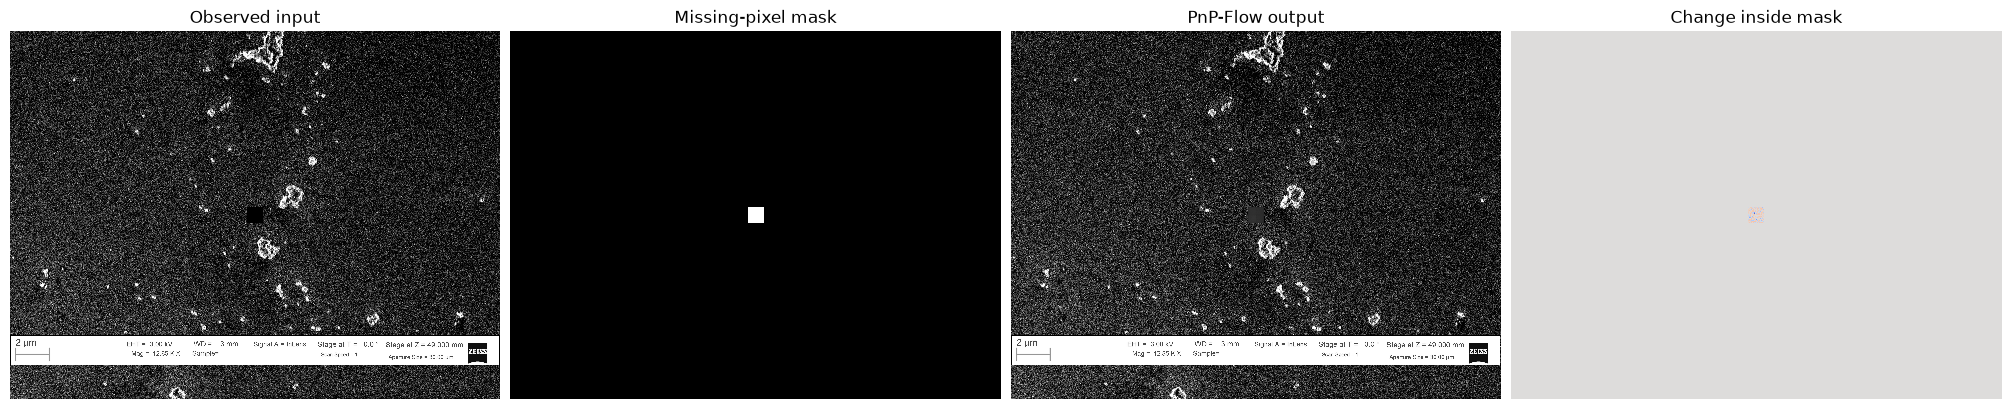

In [15]:
restored_norm = inpaint_masked_image(raw_sem_norm, missing)
# Mandatory data consistency: preserve all measured pixels exactly.
restored_norm[~missing] = raw_sem_norm[~missing]
restored_raw = raw_sem.copy()
restored_raw[missing] = ((restored_norm[missing] + 1) * 0.5 * (high - low) + low)

inside = restored_norm[missing]
print(
    f'Reconstructed normalized range inside mask: [{inside.min():.4f}, {inside.max():.4f}], '
    f'mean={inside.mean():.4f}, clamped-at--1={(inside <= -0.999).mean():.2%}'
)
known_change = np.abs(restored_raw[~missing] - raw_sem[~missing]).max()
print(f'Maximum change outside mask: {known_change:.3e}')

fig, axes = plt.subplots(1, 4, figsize=(20, 5), constrained_layout=True)
views = [observed_raw, missing, restored_raw, np.where(missing, restored_raw - raw_sem, 0)]
titles = ['Observed input', 'Missing-pixel mask', 'PnP-Flow output', 'Change inside mask']
for axis, view, title in zip(axes, views, titles):
    if title == 'Missing-pixel mask':
        axis.imshow(view, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
    elif title == 'Change inside mask':
        max_change = max(float(np.abs(view).max()), 1e-6)
        axis.imshow(view, cmap='coolwarm', vmin=-max_change, vmax=max_change, interpolation='nearest')
    else:
        axis.imshow(view, cmap='gray', vmin=low, vmax=high, interpolation='nearest')
    axis.set_title(title)
    axis.axis('off')
plt.show()


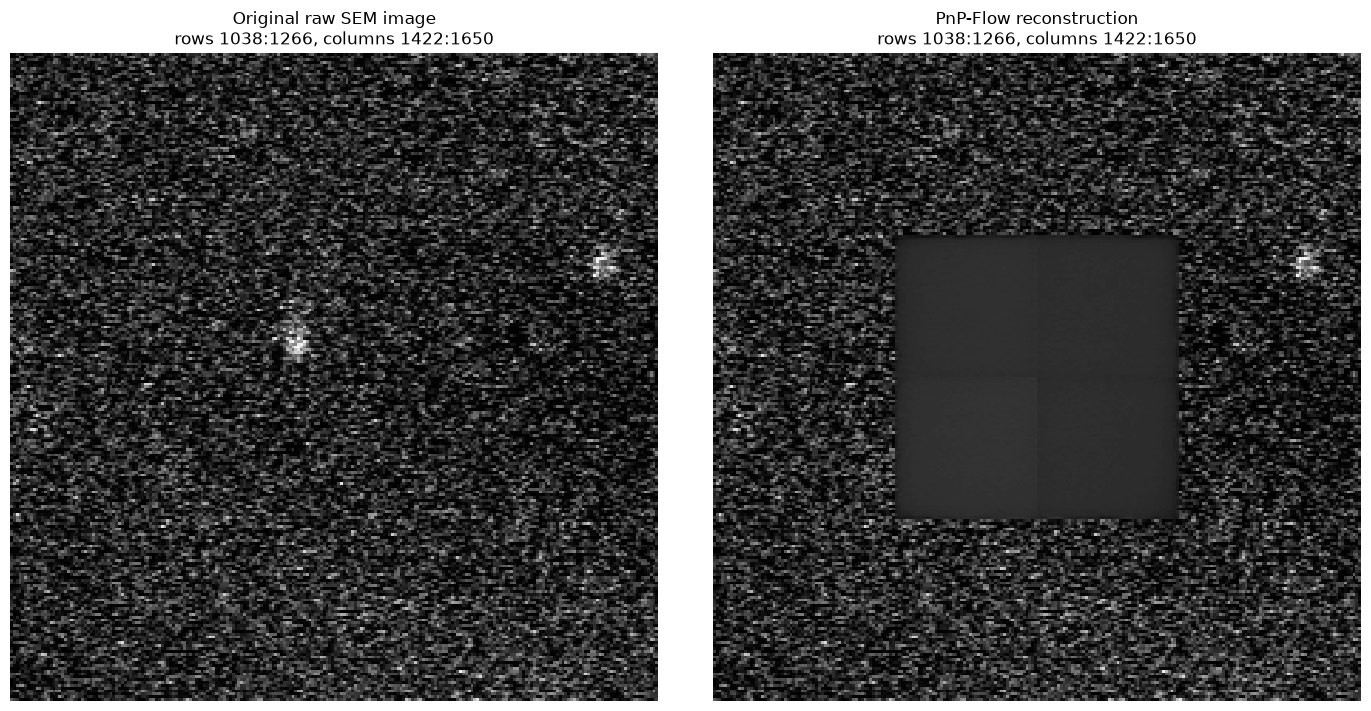

: 

In [ ]:
# Compare the original and reconstructed inpainted area with surrounding context.
ZOOM_MARGIN = 64
zoom_top = max(0, mask_top - ZOOM_MARGIN)
zoom_bottom = min(height, mask_bottom + ZOOM_MARGIN)
zoom_left = max(0, mask_left - ZOOM_MARGIN)
zoom_right = min(width, mask_right + ZOOM_MARGIN)
zoom = np.s_[zoom_top:zoom_bottom, zoom_left:zoom_right]

raw_zoom = raw_sem[zoom]
restored_zoom = restored_raw[zoom]
fig, axes = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)
for axis, image, title in zip(
    axes,
    (raw_zoom, restored_zoom),
    ('Original raw SEM image', 'PnP-Flow reconstruction'),
):
    axis.imshow(image, cmap='gray', vmin=low, vmax=high, interpolation='nearest')
    axis.set_title(f'{title}\nrows {zoom_top}:{zoom_bottom}, columns {zoom_left}:{zoom_right}')
    axis.axis('off')
plt.show()
